In [21]:
# Exploratory Data Analysis (EDA)

## Hospital Segmentation Study

#Exploratory Data Analysis is performed to understand patient demographics, hospital visits, monthly OPD trends and billing patterns.

#The analysis helps identify patterns and characteristics in the hospital dataset before performing patient segmentation.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [10]:
data_path = "../outputs/cleaned_data"

patients = pd.read_csv(f"{data_path}/patients_cleaned.csv")
opd = pd.read_csv(f"{data_path}/opd_cleaned.csv")
admissions = pd.read_csv(f"{data_path}/admissions_cleaned.csv")
lab = pd.read_csv(f"{data_path}/lab_cleaned.csv")
billing = pd.read_csv(f"{data_path}/billing_cleaned.csv")

print("All cleaned datasets loaded successfully!")

print("Patients:", patients.shape)
print("OPD:", opd.shape)
print("Admissions:", admissions.shape)
print("Lab Tests:", lab.shape)
print("Billing:", billing.shape)

All cleaned datasets loaded successfully!
Patients: (50000, 6)
OPD: (180000, 8)
Admissions: (40000, 9)
Lab Tests: (120000, 8)
Billing: (160000, 11)


In [11]:
print("PATIENT DATASET")
display(patients.head())

print("\nOPD DATASET")
display(opd.head())

print("\nBILLING DATASET")
display(billing.head())

PATIENT DATASET


,patient_id,home_hospital_id,gender,age_or_dob,patient_profile_simulation_only,age
0,P000001,H004,Male,60,Routine_Care,60
1,P000002,H002,Male,1996-07-04,Low_Utilization,29
2,P000003,H003,Male,28,Frequent_Care,28
3,P000004,H001,Female,1990-07-11,Routine_Care,35
4,P000005,H002,Male,1991-05-21,Low_Utilization,34



OPD DATASET


,visit_id,patient_id,hospital_id,doctor_id,department_id,visit_date,diagnosis_text,visit_type
0,OPD0000001,P008494,H004,DR157,D007,2024-04-22,Gastrointestinal complaint,Routine
1,OPD0000002,P011557,H001,DR006,D006,2025-08-23,Severe headache,New
2,OPD0000003,P014958,H003,DR101,D001,2025-08-11,Other complaint,Follow-up
3,OPD0000004,P014834,H002,DR072,D002,2025-06-21,High BP,New
4,OPD0000005,P040338,H004,DR151,D001,2025-01-24,Hypertension,Routine



BILLING DATASET


,bill_id,patient_id,hospital_id,doctor_id,department_id,bill_date,base_amount,gst_rate,amount_recorded,corrected_amount,gst_issue
0,BILL0000001,P029967,H001,DR023,D003,2025-06-21,2086.65,0.05,2190.98,2190.98,False
1,BILL0000002,P044033,H002,DR091,D001,2024-09-16,1276.49,0.05,1340.31,1340.31,False
2,BILL0000003,P048867,H001,DR043,D003,2025-09-14,1500.36,0.05,1650.40,1575.38,True
3,BILL0000004,P006700,H001,DR023,D003,2024-02-16,1772.28,0.05,1860.89,1860.89,False
4,BILL0000005,P008488,H003,DR124,D004,2024-10-13,1485.19,0.05,1633.71,1559.45,True


In [12]:
print("Patient Age Summary")
display(patients["age"].describe())

print("\nBilling Amount Summary")
display(billing["corrected_amount"].describe())

print("\nOPD Visit Summary")
display(opd.describe(include="all"))

Patient Age Summary


count    50000.000000
mean        51.993300
std         19.396178
min         19.000000
25%         35.000000
50%         52.000000
75%         69.000000
max         86.000000
Name: age, dtype: float64


Billing Amount Summary


count    160000.000000
mean       2839.246257
std        2701.131862
min         262.500000
25%        1214.475000
50%        2053.890000
75%        3501.590000
max       67574.340000
Name: corrected_amount, dtype: float64


OPD Visit Summary


,visit_id,patient_id,hospital_id,doctor_id,department_id,visit_date,diagnosis_text,visit_type
count,180000,180000,180000,180000,180000,180000,180000,180000
unique,180000,45287,4,200,20,731,34,3
top,OPD0179984,P012916,H001,DR024,D004,2024-07-08,Fever,Follow-up
freq,1,21,57275,2890,26912,308,7254,75787


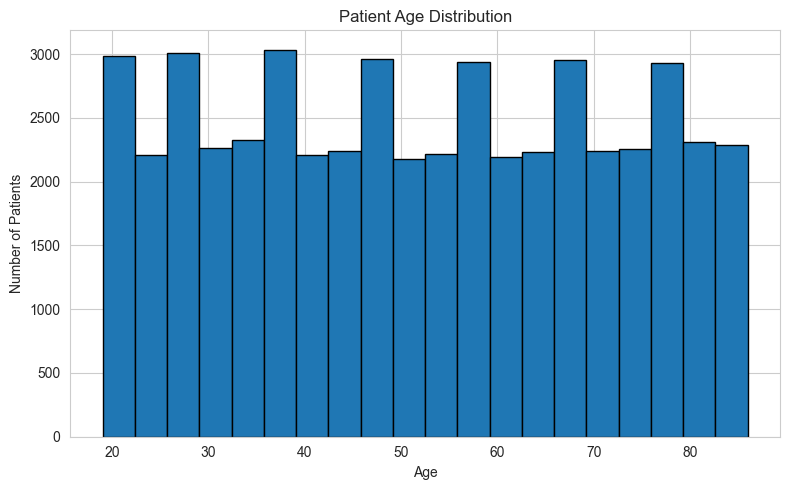

In [13]:
plt.figure(figsize=(8,5))

plt.hist(patients["age"].dropna(), bins=20, edgecolor="black")

plt.title("Patient Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

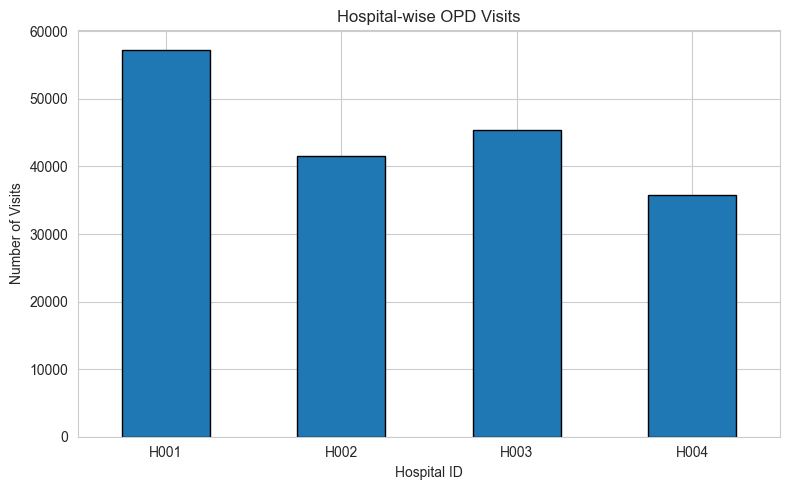

In [14]:
hospital_visits = opd["hospital_id"].value_counts().sort_index()

plt.figure(figsize=(8,5))

hospital_visits.plot(kind="bar", edgecolor="black")

plt.title("Hospital-wise OPD Visits")
plt.xlabel("Hospital ID")
plt.ylabel("Number of Visits")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

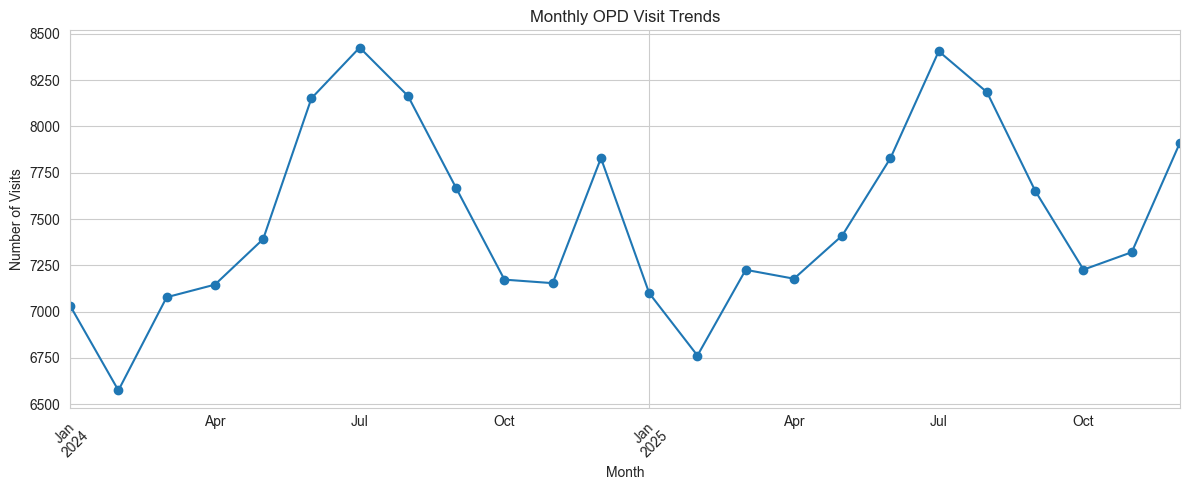

In [15]:
opd["visit_date"] = pd.to_datetime(opd["visit_date"])

monthly_visits = (
    opd.groupby(opd["visit_date"].dt.to_period("M"))
    .size()
)

plt.figure(figsize=(12,5))

monthly_visits.plot(kind="line", marker="o")

plt.title("Monthly OPD Visit Trends")
plt.xlabel("Month")
plt.ylabel("Number of Visits")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

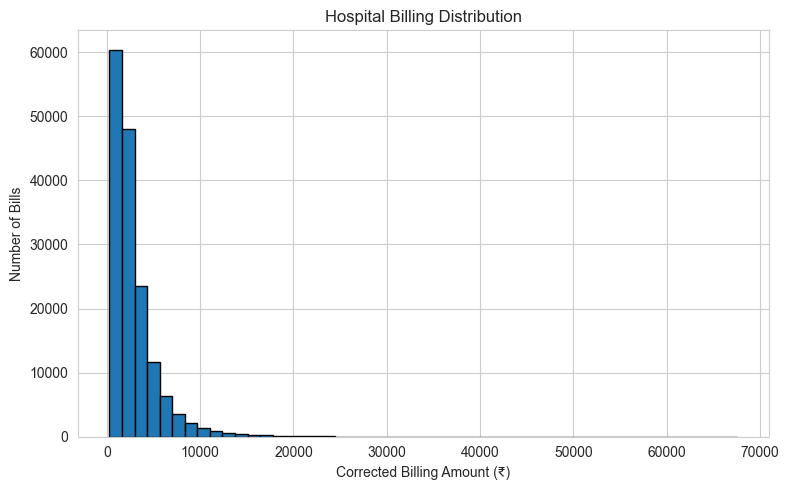

In [16]:
plt.figure(figsize=(8,5))

plt.hist(
    billing["corrected_amount"].dropna(),
    bins=50,
    edgecolor="black"
)

plt.title("Hospital Billing Distribution")
plt.xlabel("Corrected Billing Amount (₹)")
plt.ylabel("Number of Bills")

plt.tight_layout()
plt.show()

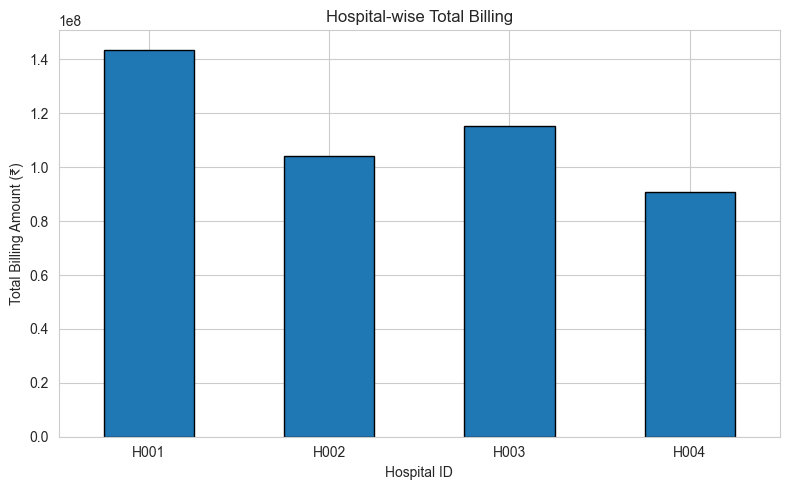

In [17]:
hospital_billing = billing.groupby("hospital_id")["corrected_amount"].sum()

plt.figure(figsize=(8,5))

hospital_billing.plot(kind="bar", edgecolor="black")

plt.title("Hospital-wise Total Billing")
plt.xlabel("Hospital ID")
plt.ylabel("Total Billing Amount (₹)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [18]:
print("EDA SUMMARY")
print("-" * 40)

print("\nTotal Patients:", len(patients))
print("Total OPD Visits:", len(opd))
print("Total Admissions:", len(admissions))
print("Total Lab Tests:", len(lab))
print("Total Bills:", len(billing))

print("\nHospital-wise OPD Visits:")
print(hospital_visits)

print("\nHospital-wise Total Billing:")
print(hospital_billing)

print("\nAverage Patient Age:", round(patients["age"].mean(), 2))
print("Average Billing Amount:",
      round(billing["corrected_amount"].mean(), 2))

EDA SUMMARY
----------------------------------------

Total Patients: 50000
Total OPD Visits: 180000
Total Admissions: 40000
Total Lab Tests: 120000
Total Bills: 160000

Hospital-wise OPD Visits:
hospital_id
H001    57275
H002    41516
H003    45383
H004    35826
Name: count, dtype: int64

Hospital-wise Total Billing:
hospital_id
H001    1.435995e+08
H002    1.043355e+08
H003    1.153716e+08
H004    9.097278e+07
Name: corrected_amount, dtype: float64

Average Patient Age: 51.99
Average Billing Amount: 2839.25


In [20]:
## EDA Conclusion

#Exploratory Data Analysis was performed to understand patient demographics, hospital-wise OPD visits, monthly visit trends and billing patterns.

#The analysis helps identify variations in patient activity and hospital billing across the four hospitals. These findings provide a foundation for patient-level segmentation using RFM features and K-Means clustering.